In [42]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


In [43]:
data= load_iris()
X=pd.DataFrame(data.data, columns=data.feature_names)
y=pd.Series(data.target)

X

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [44]:
print(f"Shape of data: {X.shape}")
print(f"Classes: {data.target_names}")
print(f"Count of each class:\n{y.value_counts()}")

Shape of data: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']
Count of each class:
0    50
1    50
2    50
Name: count, dtype: int64


In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [46]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [47]:
knn=KNeighborsClassifier(n_neighbors=5,metric='manhattan')
knn.fit(X_train,y_train)


KNeighborsClassifier(metric='manhattan')

In [48]:
y_pred=knn.predict(X_test)

In [49]:
accuracy=accuracy_score(y_test,y_pred)
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 93.33%


In [50]:
cm=confusion_matrix(y_test,y_pred)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred))



Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


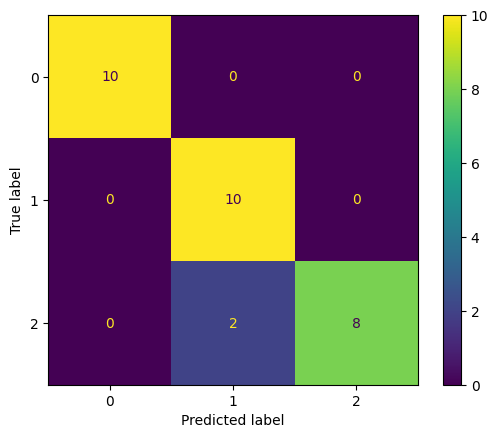

In [51]:
ConfusionMatrixDisplay(cm).plot()